<a href="https://colab.research.google.com/github/fergogu27-ctrl/EDPII/blob/main/Movimiento_Browniano_con_Deriva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movimiento browniano con deriva

**Problema.** Encuentre la probabilidad de que un movimiento browniano con deriva $\mu=0.6$ y parámetro de varianza $\sigma^2=0.25$ tome valores entre $1$ y $3$ en el tiempo $t=4$.

> Se supone que el proceso inicia en $X(0)=0$. En las expresiones $N(m,v)$, el segundo parámetro representa la **varianza**.


Calcularemos la solución analítica y simulación

## 1. Modelo matemático

Un movimiento browniano con deriva se escribe como

$$X(t)=\mu t+\sigma W(t),$$

siendo $W(t)$ un movimiento browniano estándar, por lo que $W(t)\sim N(0,t)$. En consecuencia,

$$X(t)\sim N(\mu t,\sigma^2 t).$$

Para los valores dados:

$$\mu t=0.6(4)=2.4,\qquad \sigma^2t=0.25(4)=1.$$

Así,

$$X(4)\sim N(2.4,1).$$

La probabilidad solicitada es

$$P(1<X(4)<3)=P\left(\frac{1-2.4}{1}<Z<\frac{3-2.4}{1}\right)$$

$$=P(-1.4<Z<0.6)=\Phi(0.6)-\Phi(-1.4),$$

donde $Z\sim N(0,1)$ y $\Phi$ es su función de distribución acumulada.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu = 0.6               # Parámetro de deriva
sigma_cuadrada = 0.25  # Varianza por unidad de tiempo
sigma = np.sqrt(sigma_cuadrada)
t = 4
limite_inferior = 1
limite_superior = 3

media = mu * t
varianza = sigma_cuadrada * t
desviacion = np.sqrt(varianza)

z_inferior = (limite_inferior - media) / desviacion
z_superior = (limite_superior - media) / desviacion

probabilidad_analitica = norm.cdf(z_superior) - norm.cdf(z_inferior)

print(f"X(4) ~ Normal(media={media:.2f}, varianza={varianza:.2f})")
print(f"Límites estandarizados: z_inf={z_inferior:.2f}, z_sup={z_superior:.2f}")
print(f"Φ({z_superior:.2f}) = {norm.cdf(z_superior):.6f}")
print(f"Φ({z_inferior:.2f}) = {norm.cdf(z_inferior):.6f}")
print(f"Probabilidad analítica = {probabilidad_analitica:.6f}")
print(f"Porcentaje = {100 * probabilidad_analitica:.4f}%")

X(4) ~ Normal(media=2.40, varianza=1.00)
Límites estandarizados: z_inf=-1.40, z_sup=0.60
Φ(0.60) = 0.725747
Φ(-1.40) = 0.080757
Probabilidad analítica = 0.644990
Porcentaje = 64.4990%


## 2. Simulación Monte Carlo

Como $W(4)\sim N(0,4)$, puede generarse mediante $W(4)=\sqrt{4}\,Z$ con $Z\sim N(0,1)$. Por tanto,

$$X(4)=\mu(4)+\sigma\sqrt{4}\,Z.$$

Simulamos $n$ valores independientes y estimamos la probabilidad con la proporción que queda dentro de $(1,3)$:

$$\widehat p=\frac{1}{n}\sum_{i=1}^n \mathbf{1}_{\{1<X_i(4)<3\}}.$$

La semilla permite reproducir los resultados.

In [15]:
n = 100_000  # Cantidad de simulaciones
rng = np.random.default_rng(42)

Z = rng.standard_normal(n)
X4 = mu * t + sigma * np.sqrt(t) * Z

aciertos = (X4 > limite_inferior) & (X4 < limite_superior)
probabilidad_simulada = np.mean(aciertos)
error_absoluto = abs(probabilidad_simulada - probabilidad_analitica)
error_estandar = np.sqrt(probabilidad_simulada * (1 - probabilidad_simulada) / n)

print(f"Total de simulaciones: {n:,}")
print(f"Valores en (1, 3): {np.sum(aciertos):,}")
print(f"Probabilidad simulada: {probabilidad_simulada:.6f} ({100 * probabilidad_simulada:.4f}%)")
print(f"Probabilidad analítica: {probabilidad_analitica:.6f} ({100 * probabilidad_analitica:.4f}%)")
print(f"Error absoluto:        {error_absoluto:.6f}")
print(f"Error estándar MC:     {error_estandar:.6f}")

Total de simulaciones: 100,000
Valores en (1, 3): 64,599
Probabilidad simulada: 0.645990 (64.5990%)
Probabilidad analítica: 0.644990 (64.4990%)
Error absoluto:        0.001000
Error estándar MC:     0.001512


## 3. Comparación gráfica de simulación y distribución teórica

El histograma de los valores simulados debe parecerse a la densidad normal $N(2.4,1)$. La zona sombreada muestra el evento $1<X(4)<3$.

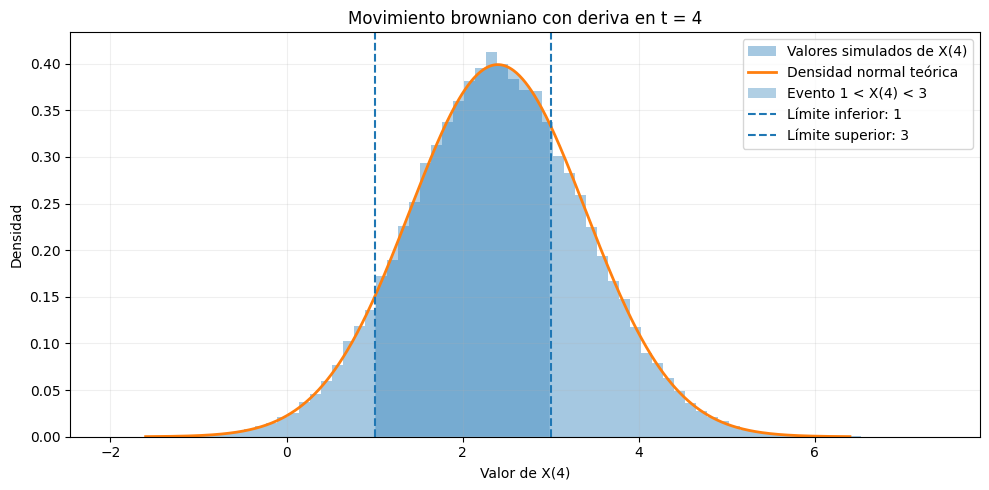

In [16]:
x = np.linspace(media - 4 * desviacion, media + 4 * desviacion, 700)
y = norm.pdf(x, loc=media, scale=desviacion)

plt.figure(figsize=(10, 5))
plt.hist(X4, bins=75, density=True, alpha=0.4, label="Valores simulados de X(4)")
plt.plot(x, y, linewidth=2, label="Densidad normal teórica")
mascara = (x >= limite_inferior) & (x <= limite_superior)
plt.fill_between(x[mascara], y[mascara], alpha=0.35, label="Evento 1 < X(4) < 3")
plt.axvline(limite_inferior, linestyle="--", linewidth=1.5, label="Límite inferior: 1")
plt.axvline(limite_superior, linestyle="--", linewidth=1.5, label="Límite superior: 3")
plt.title("Movimiento browniano con deriva en t = 4")
plt.xlabel("Valor de X(4)")
plt.ylabel("Densidad")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 4. Simulación de trayectorias completas (visualización complementaria)

Para simular las trayectorias del proceso en $[0,4]$, dividimos el tiempo en pasos $\Delta t$ y usamos

$$X(t_{k+1})-X(t_k)=\mu\Delta t+\sigma\sqrt{\Delta t}\,Z_k,$$

con incrementos normales estándar independientes $Z_k$. Esta gráfica permite ver cómo evoluciona el movimiento browniano con deriva.

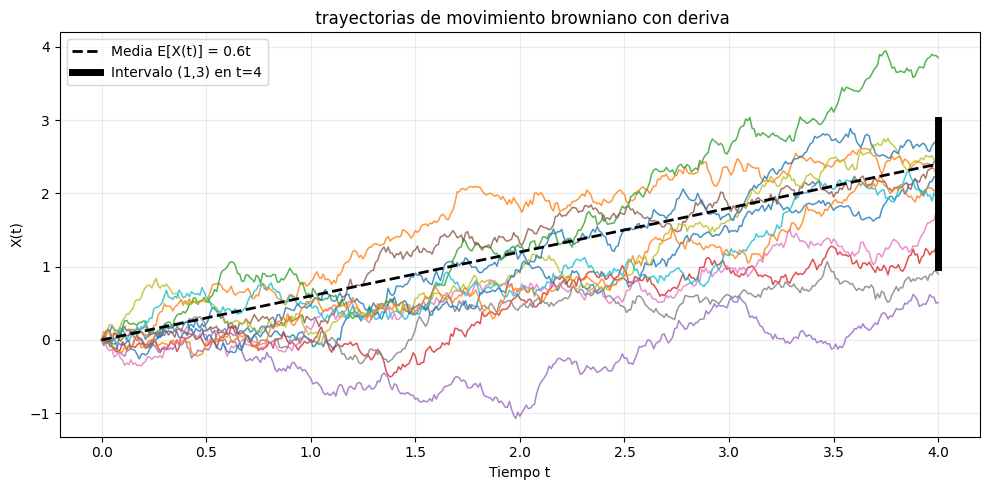

In [17]:
num_trayectorias = 12
num_pasos = 400
tiempos = np.linspace(0, t, num_pasos + 1)
delta_t = t / num_pasos

incrementos = mu * delta_t + sigma * np.sqrt(delta_t) * rng.standard_normal(
    (num_trayectorias, num_pasos)
)
trayectorias = np.concatenate(
    [np.zeros((num_trayectorias, 1)), np.cumsum(incrementos, axis=1)], axis=1
)

plt.figure(figsize=(10, 5))
for trayectoria in trayectorias:
    plt.plot(tiempos, trayectoria, linewidth=1.1, alpha=0.8)
plt.plot(tiempos, mu * tiempos, "k--", linewidth=2, label="Media E[X(t)] = 0.6t")
plt.plot([t, t], [limite_inferior, limite_superior], "k", linewidth=5,
         label="Intervalo (1,3) en t=4")
plt.xlabel("Tiempo t")
plt.ylabel("X(t)")
plt.title(" trayectorias de movimiento browniano con deriva")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

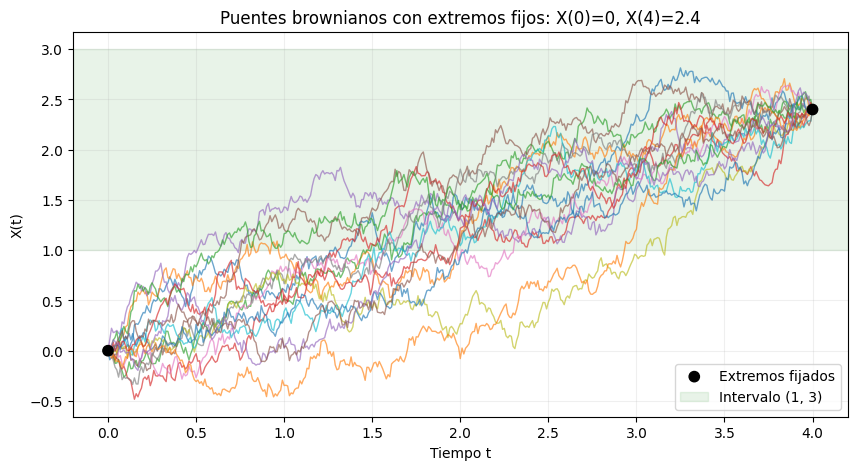

Valores al final (primeras 5 trayectorias): [2.4 2.4 2.4 2.4 2.4]
P(1 < X_puente(4) < 3) = 1 porque X_puente(4)=2.4 es fijo


In [18]:
T = 4.0
a, c = 1.0, 3.0
n_pasos = 400
n_trayectorias = 16
t = np.linspace(0, T, n_pasos + 1)
dt = t[1] - t[0]

# Movimiento browniano estándar a partir de incrementos gaussianos
dW = rng.normal(0, np.sqrt(dt), size=(n_trayectorias, n_pasos))
W = np.column_stack([np.zeros(n_trayectorias), np.cumsum(dW, axis=1)])

# Puente estándar de 0 a 0 y puente de 0 a 2.4
B = W - (t / T)[None, :] * W[:, [-1]]
b = 2.4
puentes_fijos = b * t[None, :] / T + sigma * B

fig, ax = plt.subplots(figsize=(10, 5))
for trayectoria in puentes_fijos:
    ax.plot(t, trayectoria, alpha=0.65, lw=1)
ax.scatter([0, T], [0, b], c=['black', 'black'], s=55, zorder=5, label='Extremos fijados')
ax.axhspan(a, c, color='green', alpha=0.09, label='Intervalo (1, 3)')
ax.set(title='Puentes brownianos con extremos fijos: X(0)=0, X(4)=2.4',
       xlabel='Tiempo t', ylabel='X(t)')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

print('Valores al final (primeras 5 trayectorias):', np.round(puentes_fijos[:5, -1], 6))
print(f'P(1 < X_puente(4) < 3) = {float(a < b < c):.0f} porque X_puente(4)={b} es fijo')

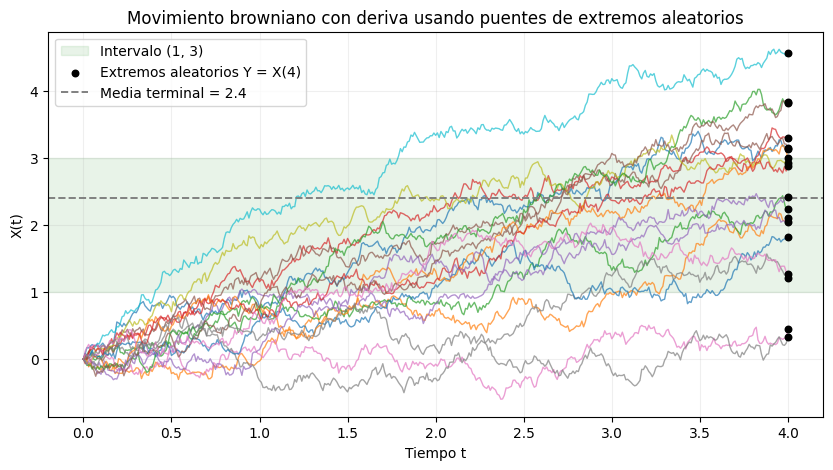

Error máximo |X(4)-Y|: 0.0


In [19]:
n_caminos = 18

# Usamos puentes estándar independientes de sus extremos aleatorios.
dW = rng.normal(0, np.sqrt(dt), size=(n_caminos, n_pasos))
W = np.column_stack([np.zeros(n_caminos), np.cumsum(dW, axis=1)])
B = W - (t / T)[None, :] * W[:, [-1]]
Y = rng.normal(loc=mu*T, scale=sigma*np.sqrt(T), size=n_caminos)
X = (t / T)[None, :] * Y[:, None] + sigma * B

fig, ax = plt.subplots(figsize=(10, 5))
for i in range(n_caminos):
    ax.plot(t, X[i], lw=1, alpha=0.7)
ax.axhspan(a, c, color='green', alpha=0.09, label='Intervalo (1, 3)')
ax.scatter(np.full(n_caminos, T), Y, s=22, color='black', zorder=5,
           label='Extremos aleatorios Y = X(4)')
ax.axhline(mu*T, ls='--', color='gray', lw=1.4, label='Media terminal = 2.4')
ax.set(title='Movimiento browniano con deriva usando puentes de extremos aleatorios',
       xlabel='Tiempo t', ylabel='X(t)')
ax.grid(alpha=0.2)
ax.legend(loc='upper left')
plt.show()

print('Error máximo |X(4)-Y|:', np.max(np.abs(X[:, -1] - Y)))

## 5. Conclusión

La solución exacta es

$$\boxed{P(1<X(4)<3)=\Phi(0.6)-\Phi(-1.4)\approx0.6449902230}.$$

Esto equivale a **aproximadamente 64.50 %**. El método Monte Carlo genera resultados próximos al valor analítico. La pequeña diferencia se debe al error de muestreo y generalmente disminuye al aumentar el número de simulaciones.